# 01 · Baseline listing segmentation

## Purpose

This notebook develops a baseline segmentation of NYC Airbnb listings using **room type** and **distance from the city centre**. These variables provide a simple description of what a listing is and where it is located.

Price is not used to form the clusters. It is introduced only after clustering so that differences in advertised price can be examined without building those differences into the segmentation itself.

The baseline is retained as a reference for comparison with a later model that adds behavioural information.

## 1. Imports

The analysis uses standard data handling, visualisation and validation libraries. The clustering routine is implemented directly so that the mixed numerical and categorical distance calculation is explicit and reproducible.

In [1]:
from pathlib import Path
from itertools import combinations

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

## 2. Configuration

The main analysis settings are kept together so that the clustering can be reproduced consistently. Candidate solutions from two to eight clusters are tested. Several random initialisations are used because clustering can converge to different local solutions.

In [2]:
RANDOM_SEED = 42
K_VALUES = range(2, 9)

N_INIT = 10
STABILITY_RUNS = 5
STABILITY_N_INIT = 3
MAX_ITER = 100

GAMMA = 1.0
MIN_CLUSTER_SHARE = 0.01
SILHOUETTE_SAMPLE_SIZE = 2_000

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airbnb_cleaned_features.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "clustering" / "baseline"
MODEL_DIR = PROJECT_ROOT / "models" / "clustering"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 3. Load and check the data

Only checks needed for the clustering are repeated here. The baseline requires a unique listing identifier, room type and distance from the city centre. Other variables are retained for profiling after the clusters have been created.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}\n"
        "Update DATA_PATH in the configuration cell if the file is stored elsewhere."
    )

df = pd.read_csv(DATA_PATH)

required_columns = {"id", "room_type", "dist_center_km"}
missing_columns = sorted(required_columns.difference(df.columns))

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df["id"].duplicated().any():
    raise ValueError("Duplicate listing IDs were found. Listing IDs must be unique.")

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print("\nMissing values in baseline fields:")
display(df[["id", "room_type", "dist_center_km"]].isna().sum().to_frame("missing"))

Rows: 31,340
Columns: 34

Missing values in baseline fields:


,missing
id,0
room_type,0
dist_center_km,0


## 4. Baseline clustering variables

Two variables are used to form the baseline clusters.

- **Room type** represents the accommodation format.
- **Distance from the city centre** represents centrality.

The model deliberately excludes price, review activity, availability, minimum stay, host characteristics and neighbourhood price measures. These are used later to describe the clusters rather than to determine them.

In [4]:
feature_definition = pd.DataFrame(
    {
        "variable": ["room_type", "dist_center_km"],
        "data_type": ["categorical", "numerical"],
        "role": ["Accommodation format", "Location and centrality"],
    }
)

display(feature_definition)

,variable,data_type,role
0,room_type,categorical,Accommodation format
1,dist_center_km,numerical,Location and centrality


## 5. Prepare the clustering inputs

K-prototypes is appropriate when numerical and categorical variables are used together. Distance from the centre is standardised before clustering. This places the numerical variable on a controlled scale before it is combined with the categorical mismatch component.

Rows missing either clustering input are excluded. The number of removed observations is reported.

In [5]:
cluster_df = df[["id", "room_type", "dist_center_km"]].copy()

rows_before = len(cluster_df)
cluster_df = cluster_df.dropna(subset=["room_type", "dist_center_km"]).reset_index(drop=True)
rows_after = len(cluster_df)

print(f"Rows before clustering checks: {rows_before:,}")
print(f"Rows retained: {rows_after:,}")
print(f"Rows excluded: {rows_before - rows_after:,}")

if len(cluster_df) < 3:
    raise ValueError("At least three complete observations are required for clustering.")

scaler = StandardScaler()

X_num = scaler.fit_transform(
    cluster_df[["dist_center_km"]].astype(float)
)

X_cat = (
    cluster_df[["room_type"]]
    .astype(str)
    .to_numpy()
)

print("\nRoom type distribution:")
display(cluster_df["room_type"].value_counts().to_frame("listings"))

print("Distance summary:")
display(cluster_df["dist_center_km"].describe().to_frame().T)

Rows before clustering checks: 31,340
Rows retained: 31,340
Rows excluded: 0

Room type distribution:


,listings
room_type,
Entire home/apt,16523
Private room,13956
Shared room,861


Distance summary:


,count,mean,std,min,25%,50%,75%,max
dist_center_km,"31,340.000",7.457,4.809,0.070,3.850,6.860,9.850,35.900


## 6. K-prototypes functions

The numerical part of the distance is based on squared Euclidean distance. The categorical part counts mismatches between a listing and the categorical prototype. `gamma` controls the balance between the two components.

For each value of `k`, several random starts are fitted and the solution with the lowest within-cluster cost is retained.

In [6]:
def categorical_modes(X_cat, labels, k, rng):
    centres = []

    for cluster_id in range(k):
        members = X_cat[labels == cluster_id]

        if len(members) == 0:
            centres.append(X_cat[rng.integers(0, len(X_cat))].copy())
            continue

        mode_row = []
        for col in range(X_cat.shape[1]):
            values, counts = np.unique(members[:, col], return_counts=True)
            mode_row.append(values[np.argmax(counts)])

        centres.append(mode_row)

    return np.asarray(centres, dtype=object)


def distances_to_prototypes(X_num, X_cat, num_centres, cat_centres, gamma=1.0):
    numeric_distance = (
        (X_num[:, None, :] - num_centres[None, :, :]) ** 2
    ).sum(axis=2)

    categorical_distance = (
        X_cat[:, None, :] != cat_centres[None, :, :]
    ).sum(axis=2)

    return numeric_distance + gamma * categorical_distance


def initialise_prototypes(X_num, X_cat, k, rng):
    indices = rng.choice(len(X_num), size=k, replace=False)
    return X_num[indices].copy(), X_cat[indices].copy()


def fit_single_kprototypes(
    X_num,
    X_cat,
    k,
    gamma=1.0,
    max_iter=100,
    random_state=42,
):
    rng = np.random.default_rng(random_state)
    num_centres, cat_centres = initialise_prototypes(X_num, X_cat, k, rng)

    previous_labels = None

    for iteration in range(max_iter):
        distances = distances_to_prototypes(
            X_num, X_cat, num_centres, cat_centres, gamma
        )
        labels = distances.argmin(axis=1)

        empty_clusters = [
            cluster_id
            for cluster_id in range(k)
            if not np.any(labels == cluster_id)
        ]

        if empty_clusters:
            nearest_distance = distances.min(axis=1)
            replacement_order = np.argsort(nearest_distance)[::-1]

            for cluster_id, row_index in zip(empty_clusters, replacement_order):
                labels[row_index] = cluster_id

        new_num_centres = np.vstack(
            [
                X_num[labels == cluster_id].mean(axis=0)
                for cluster_id in range(k)
            ]
        )

        new_cat_centres = categorical_modes(
            X_cat, labels, k, rng
        )

        if previous_labels is not None and np.array_equal(labels, previous_labels):
            num_centres = new_num_centres
            cat_centres = new_cat_centres
            break

        num_centres = new_num_centres
        cat_centres = new_cat_centres
        previous_labels = labels.copy()

    final_distances = distances_to_prototypes(
        X_num, X_cat, num_centres, cat_centres, gamma
    )

    labels = final_distances.argmin(axis=1)
    cost = final_distances[np.arange(len(labels)), labels].sum()

    return {
        "labels": labels,
        "num_centres": num_centres,
        "cat_centres": cat_centres,
        "cost": float(cost),
        "iterations": iteration + 1,
        "gamma": gamma,
    }


def fit_kprototypes(
    X_num,
    X_cat,
    k,
    gamma=1.0,
    n_init=10,
    max_iter=100,
    random_state=42,
):
    best_model = None

    for run in range(n_init):
        seed = random_state + run
        model = fit_single_kprototypes(
            X_num=X_num,
            X_cat=X_cat,
            k=k,
            gamma=gamma,
            max_iter=max_iter,
            random_state=seed,
        )

        if best_model is None or model["cost"] < best_model["cost"]:
            best_model = model

    return best_model


def mixed_distance_matrix(X_num, X_cat, gamma=1.0):
    numeric = (
        (X_num[:, None, :] - X_num[None, :, :]) ** 2
    ).sum(axis=2)

    categorical = (
        X_cat[:, None, :] != X_cat[None, :, :]
    ).sum(axis=2)

    return numeric + gamma * categorical


def clustering_stability(
    X_num,
    X_cat,
    k,
    gamma,
    runs,
    n_init,
    max_iter,
    random_state,
):
    label_sets = []

    for run in range(runs):
        model = fit_kprototypes(
            X_num=X_num,
            X_cat=X_cat,
            k=k,
            gamma=gamma,
            n_init=n_init,
            max_iter=max_iter,
            random_state=random_state + (run * 100),
        )
        label_sets.append(model["labels"])

    pair_scores = [
        adjusted_rand_score(label_sets[i], label_sets[j])
        for i, j in combinations(range(len(label_sets)), 2)
    ]

    return float(np.mean(pair_scores)) if pair_scores else np.nan

## 7. Compare candidate numbers of clusters

Candidate values of `k` are compared using several measures rather than one score alone.

- **Cost** measures within-cluster dissimilarity. It normally falls as more clusters are added.
- **Silhouette score** measures how well observations fit their own cluster relative to neighbouring clusters. Higher values indicate clearer separation.
- **Stability** uses the Adjusted Rand Index to compare solutions from repeated fits. Higher values indicate more consistent cluster membership.
- **Cluster size** is checked to avoid retaining a solution made up of very small groups.

For efficiency, silhouette is estimated from a fixed random sample when the dataset is large. The same sample is used for every candidate value of `k`.

In [7]:
candidate_k = [k for k in K_VALUES if k < len(cluster_df)]

rng = np.random.default_rng(RANDOM_SEED)
silhouette_n = min(SILHOUETTE_SAMPLE_SIZE, len(cluster_df))

silhouette_index = np.sort(
    rng.choice(
        len(cluster_df),
        size=silhouette_n,
        replace=False,
    )
)

X_num_sil = X_num[silhouette_index]
X_cat_sil = X_cat[silhouette_index]
D_silhouette = mixed_distance_matrix(
    X_num_sil,
    X_cat_sil,
    gamma=GAMMA,
)

results = []
models = {}

for k in candidate_k:
    model = fit_kprototypes(
        X_num=X_num,
        X_cat=X_cat,
        k=k,
        gamma=GAMMA,
        n_init=N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_SEED,
    )

    labels = model["labels"]
    counts = pd.Series(labels).value_counts()

    sample_labels = labels[silhouette_index]
    sample_counts = pd.Series(sample_labels).value_counts()

    silhouette = np.nan

    if (
        len(np.unique(sample_labels)) > 1
        and sample_counts.min() > 1
    ):
        silhouette = silhouette_score(
            D_silhouette,
            sample_labels,
            metric="precomputed",
        )

    stability = clustering_stability(
        X_num=X_num,
        X_cat=X_cat,
        k=k,
        gamma=GAMMA,
        runs=STABILITY_RUNS,
        n_init=STABILITY_N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_SEED,
    )

    results.append(
        {
            "k": k,
            "cost": model["cost"],
            "silhouette": silhouette,
            "stability_ari": stability,
            "smallest_cluster_n": int(counts.min()),
            "largest_cluster_n": int(counts.max()),
            "smallest_cluster_share": counts.min() / len(labels),
        }
    )

    models[k] = model

results_df = pd.DataFrame(results)
display(results_df.round(4))

,k,cost,silhouette,stability_ari,smallest_cluster_n,largest_cluster_n,smallest_cluster_share
0,2,"23,459.771",0.564,0.998,12304,19036,0.393
1,3,"15,766.243",0.557,0.999,5910,14650,0.189
2,4,"10,382.069",0.611,0.999,4085,10844,0.130
3,5,"7,487.622",0.659,0.763,2544,9732,0.081
4,6,"6,115.900",0.655,0.782,1935,7626,0.062
5,7,"4,838.383",0.643,0.751,1398,6470,0.045
6,8,"3,898.311",0.657,0.944,1019,6104,0.033


## 8. Evaluation charts

The cost curve is used to look for diminishing returns from additional clusters. Silhouette and stability provide complementary evidence about separation and repeatability.

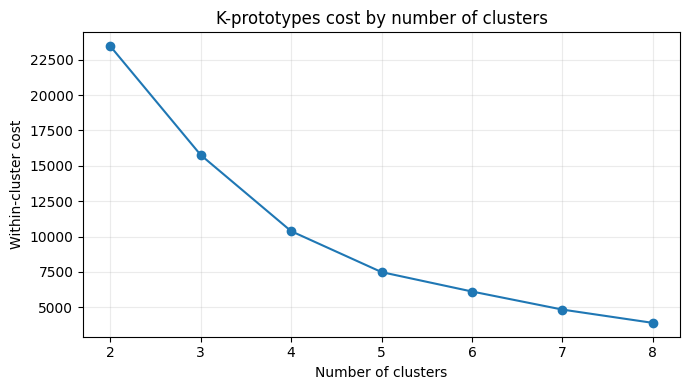

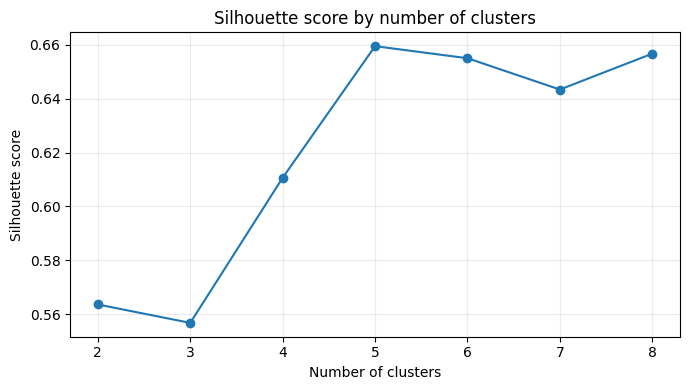

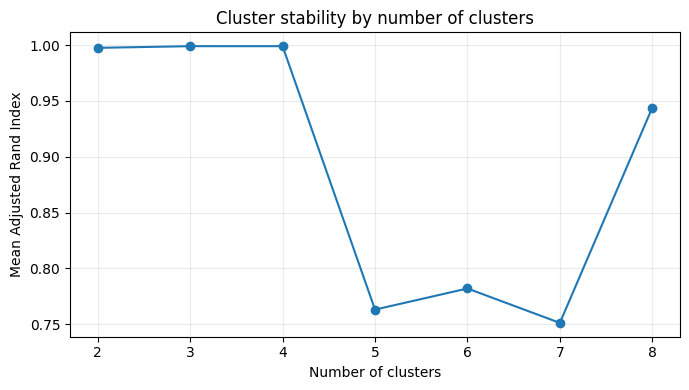

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results_df["k"], results_df["cost"], marker="o")
ax.set_title("K-prototypes cost by number of clusters")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Within-cluster cost")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results_df["k"], results_df["silhouette"], marker="o")
ax.set_title("Silhouette score by number of clusters")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Silhouette score")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results_df["k"], results_df["stability_ari"], marker="o")
ax.set_title("Cluster stability by number of clusters")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Mean Adjusted Rand Index")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Select the baseline solution

Solutions containing very small clusters are excluded where possible. Among the remaining candidates, silhouette is used as the main measure of separation and stability is used to assess repeatability.

The selected solution provides the strongest separation among the tested candidates, although some alternative values of `k` show greater stability. It is therefore retained as the baseline segmentation and assessed further through its cluster profiles.

In [9]:
minimum_cluster_n = max(
    2,
    int(np.ceil(MIN_CLUSTER_SHARE * len(cluster_df))),
)

eligible = results_df[
    results_df["smallest_cluster_n"] >= minimum_cluster_n
].copy()

if eligible.empty:
    eligible = results_df.copy()

with_silhouette = eligible.dropna(subset=["silhouette"])

if not with_silhouette.empty:
    selected_row = (
        with_silhouette
        .sort_values(
            ["silhouette", "stability_ari"],
            ascending=[False, False],
        )
        .iloc[0]
    )
else:
    selected_row = (
        eligible
        .sort_values("stability_ari", ascending=False)
        .iloc[0]
    )

SELECTED_K = int(selected_row["k"])
selected_model = models[SELECTED_K]

cluster_df["cluster"] = selected_model["labels"]

print(f"Selected baseline solution: k = {SELECTED_K}")
print(f"Minimum cluster size required: {minimum_cluster_n:,}")
display(selected_row.to_frame("value"))

Selected baseline solution: k = 5
Minimum cluster size required: 314


,value
k,5.000
cost,"7,487.622"
silhouette,0.660
stability_ari,0.763
smallest_cluster_n,"2,544.000"
largest_cluster_n,"9,732.000"
smallest_cluster_share,0.081


## 10. Inspect the cluster prototypes

The numerical prototype is converted back to kilometres for interpretation. The categorical prototype shows the room type at the centre of each cluster.

In [10]:
prototype_distance_km = scaler.inverse_transform(
    selected_model["num_centres"]
)[:, 0]

prototype_table = pd.DataFrame(
    {
        "cluster": range(SELECTED_K),
        "prototype_room_type": selected_model["cat_centres"][:, 0],
        "prototype_distance_km": prototype_distance_km,
    }
)

prototype_table["prototype_distance_km"] = (
    prototype_table["prototype_distance_km"].round(2)
)

display(prototype_table)

,cluster,prototype_room_type,prototype_distance_km
0,0,Private room,18.280
1,1,Entire home/apt,3.370
2,2,Private room,4.280
3,3,Private room,9.890
4,4,Entire home/apt,9.710


## 11. Profile the baseline segments

Cluster labels are joined back to the wider dataset for interpretation. Variables used in this section do not change the cluster assignments.

Demand is summarised only for records where the demand reliability flag is valid. This avoids treating inflated adjusted review rates from very short availability windows as directly comparable with the rest of the data.

In [11]:
label_map = cluster_df[["id", "cluster"]].copy()

profile_df = df.merge(
    label_map,
    on="id",
    how="inner",
    validate="one_to_one",
)

numeric_profile_candidates = [
    "price",
    "availability_365",
    "minimum_nights",
    "calculated_host_listings_count",
    "dist_center_km",
    "reviews_per_month",
]

numeric_profiles = [
    column
    for column in numeric_profile_candidates
    if column in profile_df.columns
]

profile_summary = (
    profile_df
    .groupby("cluster")[numeric_profiles]
    .median()
    .add_prefix("median_")
)

profile_summary.insert(
    0,
    "listings",
    profile_df.groupby("cluster").size(),
)

if {"demand_rate_year", "demand_reliable"}.issubset(profile_df.columns):
    reliable_demand = profile_df.loc[
        profile_df["demand_reliable"].eq(1)
        & profile_df["demand_rate_year"].notna()
    ]

    demand_summary = (
        reliable_demand
        .groupby("cluster")["demand_rate_year"]
        .agg(
            reliable_demand_n="size",
            median_demand_rate_year="median",
        )
    )

    profile_summary = profile_summary.join(
        demand_summary,
        how="left",
    )

display(profile_summary.round(2))

,listings,median_price,median_availability_365,median_minimum_nights,median_calculated_host_listings_count,median_dist_center_km,median_reviews_per_month,reliable_demand_n,median_demand_rate_year
cluster,,,,,,,,,
0,2544,72.000,183.000,2.000,2.000,17.590,1.140,2389,24.470
1,9732,199.000,180.000,3.000,1.000,3.380,0.570,7954,13.050
2,5887,90.000,149.000,2.000,2.000,4.820,1.000,4851,22.260
3,6917,60.000,167.000,2.000,2.000,9.460,0.960,5987,22.450
4,6260,135.000,144.000,3.000,1.000,9.260,1.180,4994,33.200


In [12]:
def mode_or_nan(series):
    mode = series.dropna().mode()
    return mode.iloc[0] if len(mode) else np.nan


categorical_profile_candidates = [
    "room_type",
    "availability_bucket",
    "stay_regime",
    "neighbourhood_group",
    "nbhd_price_tier",
    "is_luxury_v2",
]

categorical_profiles = [
    column
    for column in categorical_profile_candidates
    if column in profile_df.columns
]

if categorical_profiles:
    categorical_summary = (
        profile_df
        .groupby("cluster")[categorical_profiles]
        .agg(mode_or_nan)
    )

    display(categorical_summary)

,room_type,availability_bucket,stay_regime,neighbourhood_group,nbhd_price_tier,is_luxury_v2
cluster,,,,,,
0,Private room,always-on,short (<=7),Queens,mid,0
1,Entire home/apt,half-year,short (<=7),Manhattan,top,0
2,Private room,seasonal,short (<=7),Manhattan,top,0
3,Private room,seasonal,short (<=7),Brooklyn,premium,0
4,Entire home/apt,seasonal,short (<=7),Brooklyn,premium,0


## 12. Baseline segment charts

The charts below are descriptive. They are used to check whether the selected solution produces groups that differ in understandable ways.

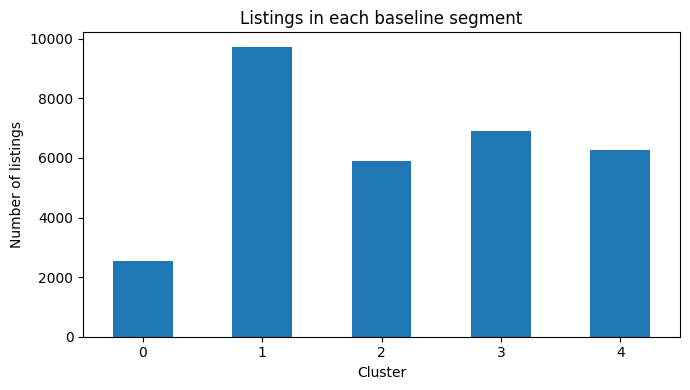

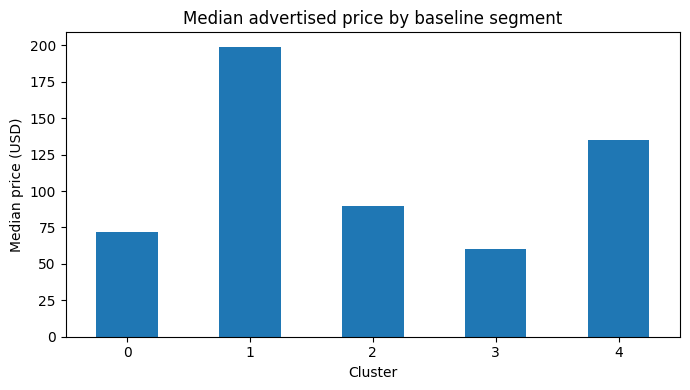

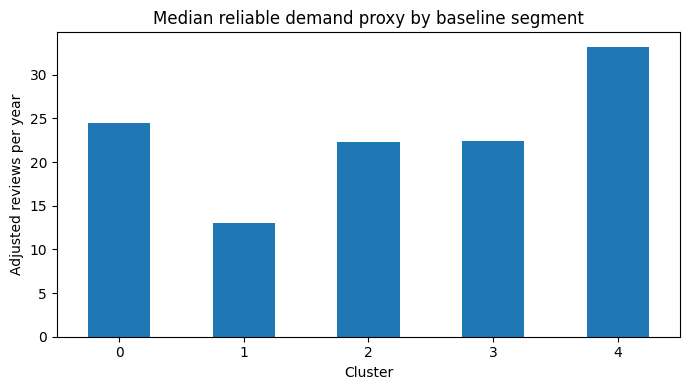

In [13]:
cluster_sizes = profile_df["cluster"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
cluster_sizes.plot(kind="bar", ax=ax)
ax.set_title("Listings in each baseline segment")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of listings")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

if "price" in profile_df.columns:
    median_price = profile_df.groupby("cluster")["price"].median()

    fig, ax = plt.subplots(figsize=(7, 4))
    median_price.plot(kind="bar", ax=ax)
    ax.set_title("Median advertised price by baseline segment")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Median price (USD)")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

if {"demand_rate_year", "demand_reliable"}.issubset(profile_df.columns):
    reliable_demand_plot = profile_df.loc[
        profile_df["demand_reliable"].eq(1)
        & profile_df["demand_rate_year"].notna()
    ]

    if not reliable_demand_plot.empty:
        median_demand = (
            reliable_demand_plot
            .groupby("cluster")["demand_rate_year"]
            .median()
        )

        fig, ax = plt.subplots(figsize=(7, 4))
        median_demand.plot(kind="bar", ax=ax)
        ax.set_title("Median reliable demand proxy by baseline segment")
        ax.set_xlabel("Cluster")
        ax.set_ylabel("Adjusted reviews per year")
        ax.tick_params(axis="x", rotation=0)
        plt.tight_layout()
        plt.show()

room_type,Entire home/apt,Private room,Shared room
cluster,,,
0,35.800,60.000,4.200
1,98.000,0.000,2.000
2,0.000,96.900,3.100
3,0.000,97.200,2.800
4,97.000,0.000,3.000


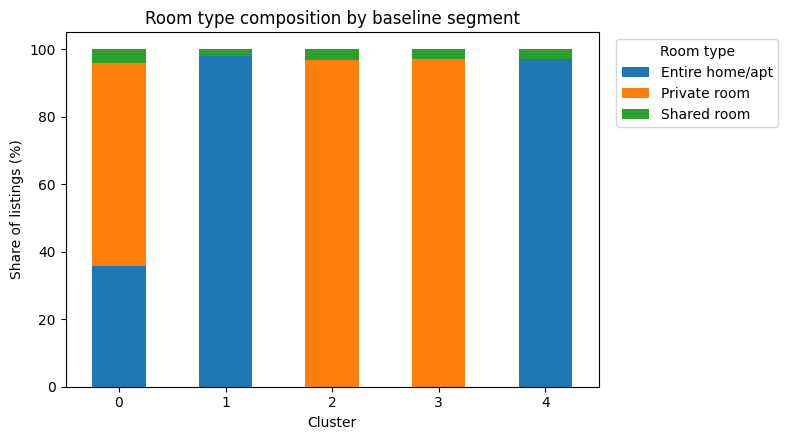

In [14]:
room_type_composition = (
    pd.crosstab(
        profile_df["cluster"],
        profile_df["room_type"],
        normalize="index",
    )
    .mul(100)
    .sort_index()
)

display(room_type_composition.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
room_type_composition.plot(
    kind="bar",
    stacked=True,
    ax=ax,
)
ax.set_title("Room type composition by baseline segment")
ax.set_xlabel("Cluster")
ax.set_ylabel("Share of listings (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Room type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 13. Baseline assessment

The five-cluster solution provides the strongest silhouette score among the tested candidates and produces interpretable groups based on accommodation type and centrality. Its stability is lower than some alternative solutions, so it is retained as a baseline for comparison rather than treated as a definitive segmentation.

A more detailed model should only be preferred if additional behavioural variables produce segments that are at least as stable and clearly more useful to interpret.

In [15]:
selected_sizes = (
    cluster_df["cluster"]
    .value_counts()
    .sort_index()
)

print("BASELINE CLUSTERING SUMMARY")
print("---------------------------")
print(f"Listings clustered: {len(cluster_df):,}")
print(f"Selected k: {SELECTED_K}")
print(f"Smallest cluster: {selected_sizes.min():,} listings")
print(f"Largest cluster: {selected_sizes.max():,} listings")

if pd.notna(selected_row["silhouette"]):
    print(f"Silhouette score: {selected_row['silhouette']:.3f}")
else:
    print("Silhouette score: not available for this solution.")

print(f"Stability ARI: {selected_row['stability_ari']:.3f}")

BASELINE CLUSTERING SUMMARY
---------------------------
Listings clustered: 31,340
Selected k: 5
Smallest cluster: 2,544 listings
Largest cluster: 9,732 listings
Silhouette score: 0.660
Stability ARI: 0.763


## 14. Save results

The selected labels, evaluation results, cluster profiles and prototypes are saved so that the same baseline can be compared with later segmentation results. The fitted clustering parameters and scaler are also stored for reproducibility.

In [16]:
labels_path = OUTPUT_DIR / "baseline_cluster_labels.csv"
evaluation_path = OUTPUT_DIR / "baseline_cluster_evaluation.csv"
profiles_path = OUTPUT_DIR / "baseline_cluster_profiles.csv"
prototypes_path = OUTPUT_DIR / "baseline_cluster_prototypes.csv"

model_path = MODEL_DIR / "baseline_kprototypes.joblib"
scaler_path = MODEL_DIR / "baseline_distance_scaler.joblib"

cluster_df[["id", "cluster"]].to_csv(labels_path, index=False)
results_df.to_csv(evaluation_path, index=False)
profile_summary.reset_index().to_csv(profiles_path, index=False)
prototype_table.to_csv(prototypes_path, index=False)

joblib.dump(selected_model, model_path)
joblib.dump(scaler, scaler_path)

print(f"Saved labels: {labels_path}")
print(f"Saved evaluation: {evaluation_path}")
print(f"Saved profiles: {profiles_path}")
print(f"Saved prototypes: {prototypes_path}")
print(f"Saved model: {model_path}")
print(f"Saved scaler: {scaler_path}")

Saved labels: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\baseline\baseline_cluster_labels.csv
Saved evaluation: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\baseline\baseline_cluster_evaluation.csv
Saved profiles: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\baseline\baseline_cluster_profiles.csv
Saved prototypes: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\baseline\baseline_cluster_prototypes.csv
Saved model: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\models\clustering\baseline_kprototypes.joblib
Saved scaler: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\models\clustering\baseline_distance_scaler.joblib
